# Parte 0 – Exploración del dataset (contextualización)

Antes de procesar las imágenes hay que **conocerlas**: cuántas hay de cada clase, cómo se ven, qué tamaño tienen, en qué formato vienen y qué "suciedad" traen. Todo lo que encontremos acá va a la sección de **contextualización** del informe y justifica decisiones de las partes siguientes.

**Contenido**
1. Cargar la lista de casos y ver cuántos hay por clase
2. Ver ejemplos de cada clase con la máscara del radiólogo
3. Medir tamaño y tamaño de la lesión de las 780 imágenes
4. Formato de las imágenes: canales, bits, color y rango de intensidades
5. Histogramas de intensidad
6. Resumen de la exploración

### Preparación

Esta celda le dice a Python dónde está nuestro código (`src/`), para poder importar las funciones de `busi`. `autoreload` hace que, si cambiamos algo en un archivo `.py`, el notebook use la versión nueva sin tener que reiniciarlo.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))

%load_ext autoreload
%autoreload 2

## 1. Lista de casos y cantidad por clase

`listar_casos()` (en `src/busi/datos.py`) recorre las carpetas `benign/`, `malignant/` y `normal/` y arma una **tabla** (un *DataFrame* de pandas) con una fila por imagen: su nombre, su clase, la ruta del archivo y las rutas de sus máscaras.

`value_counts()` cuenta cuántas filas hay de cada clase.

In [2]:
from busi.datos import listar_casos, cargar_caso

casos = listar_casos()            # tabla con una fila por imagen
casos['clase'].value_counts()     # cuántas imágenes hay de cada clase

clase
benign       437
malignant    210
normal       133
Name: count, dtype: int64

**Qué vemos:** 437 benignas (56 %), 210 malignas (27 %) y 133 normales (17 %).

Las clases están **desbalanceadas**: hay el doble de benignas que de malignas. Hay que tenerlo en cuenta en la Parte 6, porque un clasificador que diga siempre "benigno" ya acertaría el 68 % de las veces sin aprender nada. Por eso ahí vamos a usar métricas como sensibilidad y especificidad, y no solo el porcentaje de aciertos.

## 2. Ejemplos visuales de cada clase

Mostramos 4 imágenes al azar de cada clase. En rojo se dibuja el **borde de la máscara** que hizo el radiólogo, o sea, dónde está el tumor según el especialista. Las imágenes normales no tienen tumor, así que no tienen borde rojo.

En el título de cada imagen aparece su nombre y su tamaño en píxeles: `(alto, ancho)`.

Se muestran 4 casos de cada clase (benign, malignant, normal) con sus máscaras de lesión en rojo.


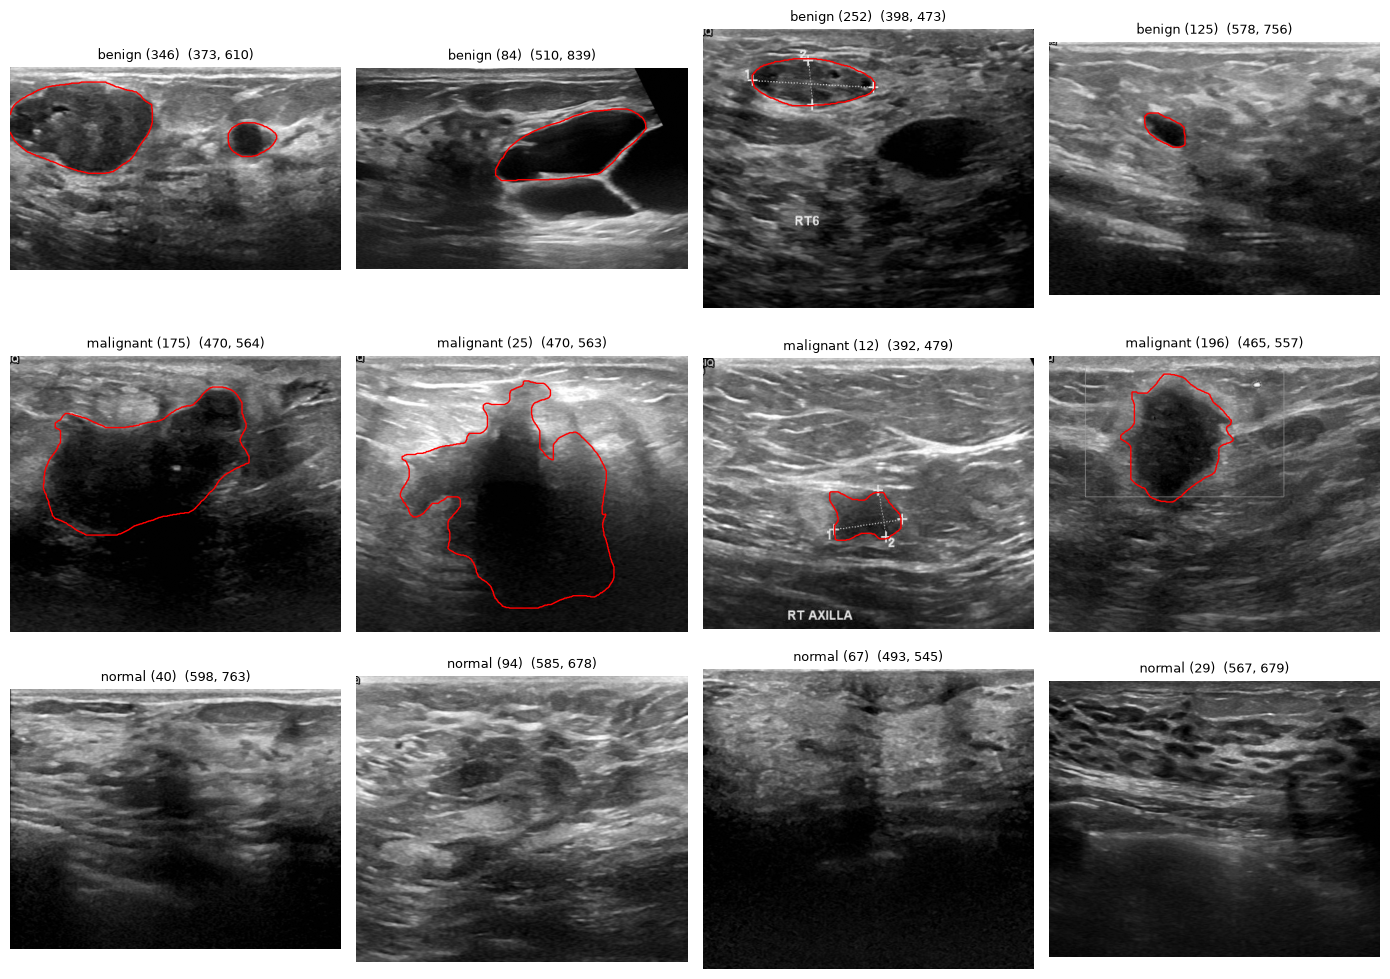

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 4, figsize=(14, 10))   # arma una grilla de 12 recuadros: una fila por clase, 4 casos

for fila, clase in zip(axes, ["benign", "malignant", "normal"]):
    # 4 casos al azar de esta clase (random_state fijo = elige una vez al azar y luego siempre los mismos para que veamos las 3 la misma grilla)
    ejemplos = casos[casos["clase"] == clase].sample(4, random_state=13)

    for ax, (_, caso) in zip(fila, ejemplos.iterrows()):
        img, mascara = cargar_caso(caso)                 # imagen + máscara del radiólogo
        ax.imshow(img, cmap="gray")
        if mascara.any():                                # las "normal" no tienen lesión
            ax.contour(mascara, levels=[0.5], colors="red", linewidths=1)  # borde en rojo
        ax.set_title(f"{caso['id']}  {img.shape}", fontsize=9)
        ax.axis("off")

plt.tight_layout()
print("Se muestran 4 casos de cada clase (benign, malignant, normal) con sus máscaras de lesión en rojo.")
plt.show()

### Observaciones

1. **Tamaño variable:** las imágenes no tienen un tamaño fijo de 500 × 500 px como indica el artículo del dataset; en esta muestra ya se ven tamaños distintos. Se cuantifica en la sección 3.
2. **Lesiones benignas:** forma ovalada o redondeada, bordes lisos y bien definidos, interior hipoecoico (oscuro) y bastante homogéneo.
3. **Lesiones malignas:** bordes irregulares, con lobulaciones o proyecciones; en algunos casos aparece una **sombra acústica posterior** (zona oscura debajo de la lesión). Coincide con los rasgos de malignidad de BI-RADS.
4. **Marcas del ecógrafo:** se observan *calipers* (cruces de medición), líneas punteadas, textos (ej. "RT AXILLA", "RT6") y recuadros superpuestos a la imagen. No son tejido.
5. **Marcas sobre la lesión:** en varias imágenes los *calipers* caen justo sobre el borde del tumor, por lo que alterarían la textura y la segmentación. Esto justifica la etapa de reconstrucción (Parte 1).

## 3. Medidas de las 780 imágenes

Ahora pasamos de mirar 12 imágenes a **medir todas**. Para cada imagen guardamos:

| Columna | Qué es |
|---|---|
| `alto`, `ancho` | tamaño de la imagen en píxeles |
| `canales`, `color`, `tipo`, `min`, `max` | datos del formato (se explican en la sección 4) |
| `frac_lesion` | qué fracción de la imagen ocupa el tumor (0,10 = 10 %) |

`frac_lesion` se calcula como el **promedio de la máscara**: la máscara vale 1 en el tumor y 0 afuera, así que su promedio es justo la proporción de píxeles que son tumor.

Al final, `describe()` resume cada medida por clase (se explica abajo de la tabla).

In [4]:
import numpy as np
import pandas as pd
from skimage import io

filas = []
for _, caso in casos.iterrows():                       # recorre las 780 imágenes
    original = io.imread(caso["ruta"])                 # la imagen tal cual viene en el PNG
    img, mascara = cargar_caso(caso)                   # en gris + máscara unida
    filas.append({
        "alto": img.shape[0],
        "ancho": img.shape[1],
        "canales": 1 if original.ndim == 2 else original.shape[2],
        "color": original.ndim == 3 and not (
            np.array_equal(original[..., 0], original[..., 1])
            and np.array_equal(original[..., 1], original[..., 2])),
        "tipo": str(original.dtype),                   # uint8 = 8 bits = 256 niveles
        "min": img.min(),
        "max": img.max(),
        "frac_lesion": mascara.mean(),                 # fracción de la imagen ocupada por la lesión
    })

casos = pd.concat([casos, pd.DataFrame(filas)], axis=1)   # agrega las columnas a la tabla
casos.groupby("clase")[["alto", "ancho", "frac_lesion"]].describe().round(2).T

clase               benign  malignant  normal
alto        count   437.00     210.00  133.00
            mean    495.47     494.01  532.85
            std      78.14      60.43   86.92
            min     324.00     332.00  310.00
            25%     464.00     463.00  470.00
            50%     471.00     474.00  493.00
            75%     574.00     554.00  587.00
            max     719.00     677.00  712.00
ancho       count   437.00     210.00  133.00
            mean    613.39     597.97  651.17
            std     117.26     125.22  126.06
            min     315.00     190.00  391.00
            25%     554.00     552.00  556.00
            50%     563.00     564.00  616.00
            75%     706.00     649.75  765.00
            max    1028.00    1048.00  948.00
frac_lesion count   437.00     210.00  133.00
            mean      0.07       0.15    0.00
            std       0.08       0.11    0.00
            min       0.00       0.01    0.00
            25%       0.02       0.06    0.00
            50%       0.04       0.12    0.00
            75%       0.09       0.21    0.00
            max       0.51       0.56    0.00

### Cómo leer la tabla

Cada **columna** es una clase y las **filas** vienen en tres grupos de 8: `alto`, `ancho` y `frac_lesion`. Las 8 filas de cada grupo resumen esa medida:

- `count`: cuántas imágenes · `mean`: promedio · `std`: desvío estándar (cuánto varían)
- `min` / `max`: el valor más chico y el más grande
- `25%`, `50%`, `75%`: el 25 %, 50 % y 75 % de las imágenes tiene un valor menor a ese número. El `50%` es la **mediana**.

### Qué vemos

- **El tamaño varía mucho:** el alto va de 310 a 719 px y el ancho de 190 a 1048 px. El artículo del dataset habla de ~500 × 500 px, pero eso es solo un promedio. Para el análisis de textura conviene trabajar con ventanas en píxeles (no relativas al tamaño de la imagen).
- **Los tumores malignos ocupan más parte de la imagen:** mediana de **12 %** en malignos contra **4 %** en benignos (fila `50%` de `frac_lesion`). Es la primera diferencia entre clases que encontramos.

### Lo mismo, en gráfico

Un **boxplot** muestra lo mismo que la tabla pero de forma visual: la línea del medio de la caja es la mediana, la caja va del 25 % al 75 % y los bigotes y puntos muestran los valores extremos.

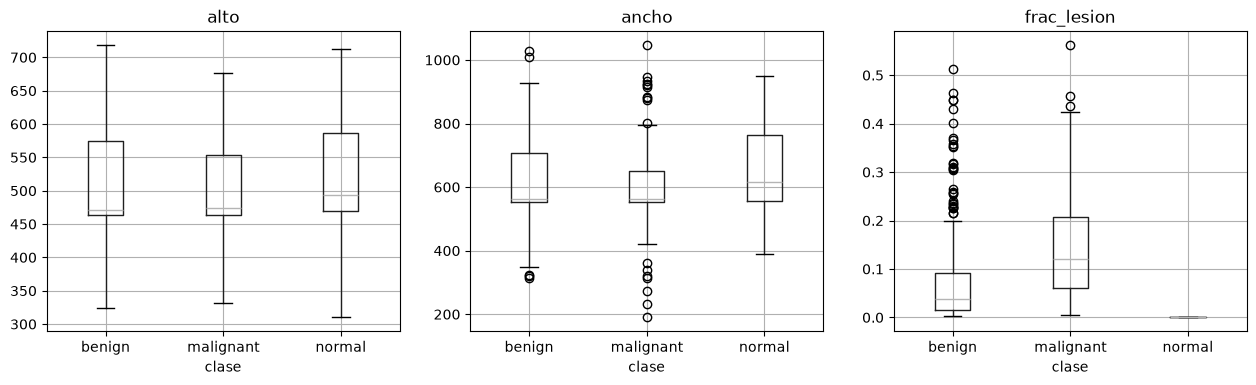

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, columna in zip(axes, ["alto", "ancho", "frac_lesion"]):
    casos.boxplot(column=columna, by="clase", ax=ax)
    ax.set_title(columna)
plt.suptitle("")
plt.show()

A simple vista no alcanza para decir si las clases difieren: las cajas se superponen, pero las medianas no son iguales y hay valores extremos. Para decidirlo usamos un **test estadístico**.

Usamos la prueba **U de Mann-Whitney**, que compara dos grupos sin suponer que los datos siguen una distribución normal (los tamaños claramente no la siguen: hay muchos valores extremos). Responde a la pregunta: *¿los valores de un grupo tienden a ser mayores que los del otro?* El resultado es un **p-valor**:
- **p < 0,05**: la diferencia es **significativa** (es muy poco probable que se deba al azar).
- **p ≥ 0,05**: **no hay evidencia** de diferencia entre los grupos.

Comparamos las clases de a pares.

In [6]:
from scipy.stats import mannwhitneyu

pares = [("benign", "malignant"), ("benign", "normal"), ("malignant", "normal")]

for columna in ["alto", "ancho", "frac_lesion"]:
    print(f"--- {columna} ---")
    for a, b in pares:
        if columna == "frac_lesion" and "normal" in (a, b):
            continue    # las normales no tienen lesión
        grupo_a = casos[casos["clase"] == a][columna]
        grupo_b = casos[casos["clase"] == b][columna]
        p = mannwhitneyu(grupo_a, grupo_b).pvalue
        resultado = "diferencia significativa" if p < 0.05 else "sin diferencia significativa"
        print(f"{a:9s} (mediana {grupo_a.median():7.2f})  vs  {b:9s} (mediana {grupo_b.median():7.2f}):  p = {p:.4f}  ->  {resultado}")

--- alto ---
benign    (mediana  471.00)  vs  malignant (mediana  474.00):  p = 0.7487  ->  sin diferencia significativa
benign    (mediana  471.00)  vs  normal    (mediana  493.00):  p = 0.0000  ->  diferencia significativa
malignant (mediana  474.00)  vs  normal    (mediana  493.00):  p = 0.0000  ->  diferencia significativa
--- ancho ---
benign    (mediana  563.00)  vs  malignant (mediana  564.00):  p = 0.4267  ->  sin diferencia significativa
benign    (mediana  563.00)  vs  normal    (mediana  616.00):  p = 0.0237  ->  diferencia significativa
malignant (mediana  564.00)  vs  normal    (mediana  616.00):  p = 0.0077  ->  diferencia significativa
--- frac_lesion ---
benign    (mediana    0.04)  vs  malignant (mediana    0.12):  p = 0.0000  ->  diferencia significativa


**Qué vemos:**

- **Benignas vs. malignas:** el tamaño de la imagen **no difiere** (alto: medianas 471 vs 474 px, p = 0,75; ancho: 563 vs 564 px, p = 0,43). Lo que sí se ve en el gráfico es que el ancho de las malignas tiene **más valores extremos**, con imágenes muy angostas (hasta 190 px) y muy anchas (hasta 1048 px), pero su mediana es la misma.
- **Normales:** son **algo más grandes** que las otras dos clases (mediana de alto 493 px y de ancho 616 px) y la diferencia es significativa (p < 0,05).
- **Fracción de lesión:** los tumores malignos ocupan una parte **significativamente mayor** de la imagen que los benignos (medianas 12 % vs 4 %).

**Implicancia:** como el tamaño de la imagen no difiere entre benignas y malignas, no introduce un sesgo en la comparación entre esas dos clases, que es la que nos interesa. La diferencia de las normales no afecta, porque no se usan en la clasificación (no tienen lesión).

## 4. Formato de las imágenes

Para entender esta sección hacen falta dos conceptos:

**Canales (gris o color).** Una imagen digital es una tabla de números, uno por píxel.
- En **escala de grises** hay **un número por píxel**: 0 = negro, 255 = blanco, en el medio los grises. Es *una sola* tabla.
- En **color (RGB)** hay **tres números por píxel**: cuánto rojo, cuánto verde y cuánto azul. Son *tres* tablas apiladas; cada una es un **canal**.

Una ecografía es naturalmente **gris**, así que con un canal alcanza.

**Tipo de dato `uint8` (profundidad de píxel).** Indica cuántos valores distintos puede tomar cada píxel. `uint8` = 8 bits = 2⁸ = **256 niveles**, de 0 a 255.

Vamos a responder cuatro preguntas, una por celda.

### 4.1 ¿Cuántos canales tienen y de qué tipo son?

In [7]:
print("Canales por imagen:", casos["canales"].value_counts().to_dict())
print("Tipo de dato:      ", casos["tipo"].value_counts().to_dict())

Canales por imagen: {3: 780}
Tipo de dato:       {'uint8': 780}


**Qué vemos:** las 780 imágenes tienen **3 canales** y son **`uint8`** (256 niveles). Es decir, están **guardadas como si fueran a color**, aunque son ecografías.

### 4.2 ¿Tienen color de verdad?

Si una imagen gris se guarda en RGB, sus tres canales tienen **exactamente los mismos números** (es gris "disfrazado" de color). La columna `color` vale `True` cuando los tres canales **no** son iguales, o sea, cuando la imagen tiene color real.

In [8]:
en_color = casos[casos["color"]]
print(f"Imágenes con color real: {len(en_color)} de {len(casos)}")
en_color[["id", "clase"]]

Imágenes con color real: 16 de 780


,id,clase
4,benign (102),benign
34,benign (13),benign
82,benign (173),benign
150,benign (234),benign
157,benign (240),benign
173,benign (255),benign
180,benign (261),benign
197,benign (277),benign
249,benign (323),benign
257,benign (330),benign


Veamos cómo son. Acá **no** usamos `cmap="gray"`, para que se vean con sus colores originales:

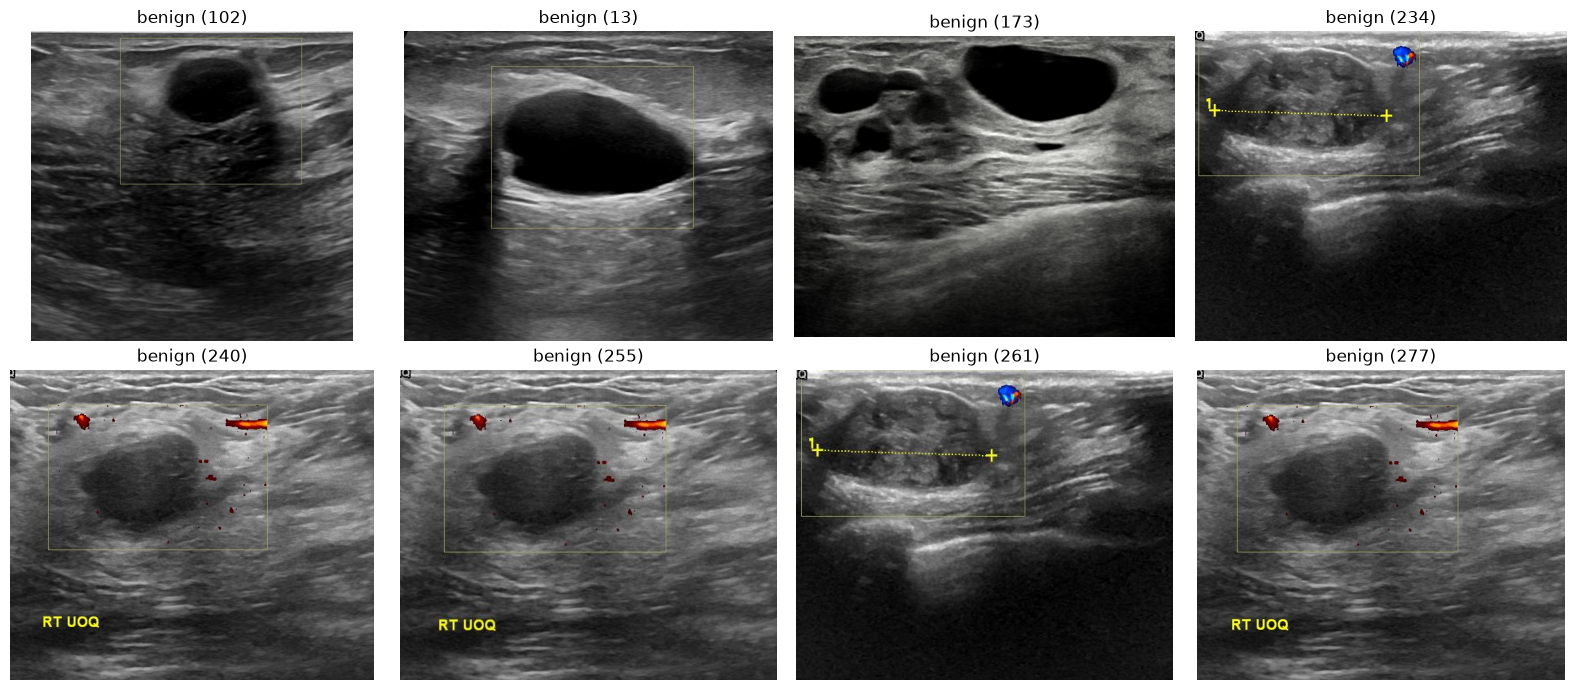

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, (_, caso) in zip(axes.flat, en_color.head(8).iterrows()):
    ax.imshow(io.imread(caso["ruta"]))      # imagen original, en color
    ax.set_title(caso["id"])
    ax.axis("off")
plt.tight_layout()
plt.show()

**Qué vemos:** 764 imágenes son grises (sus 3 canales son idénticos) y **solo 16 tienen color real**. El color **no es tejido**: son **marcas del ecógrafo** dibujadas encima:
- manchas **rojas y azules** de **Doppler** (muestran flujo sanguíneo),
- **cruces y líneas amarillas** (*calipers* de medición) y **textos amarillos** (ej. "RT UOQ"),
- **recuadros** que delimitan la zona analizada.

Consecuencias:
- Nuestra función `cargar_imagen` se queda con **un solo canal** (el rojo). Para las 764 grises da igual cuál, pero en estas 16 algunas marcas pueden verse distinto según el canal. Lo tenemos en cuenta en la **Parte 1 (artefactos)**: el color es una pista extra para detectar marcas.
- Algunas imágenes parecen **casi idénticas** entre sí (por ejemplo benign 240, 255 y 277). Es un problema conocido de BUSI: hay **duplicados**. Hay que revisarlo, porque si la misma imagen cae en entrenamiento y en prueba del clasificador, los resultados quedan inflados.

### 4.3 ¿Usan todo el rango de intensidades?

Para cada imagen guardamos su píxel **más oscuro** (`min`) y su píxel **más claro** (`max`). Contamos cuántas llegan a los extremos 0 (negro puro) y 255 (blanco puro).

In [10]:
print(f"Imágenes con algún píxel negro puro (min = 0):    {(casos['min'] == 0).sum()} de {len(casos)}")
print(f"Imágenes con algún píxel blanco puro (max = 255): {(casos['max'] == 255).sum()} de {len(casos)}")
print(f"El 'max' más bajo de todo el dataset es: {casos['max'].min()}")

Imágenes con algún píxel negro puro (min = 0):    762 de 780
Imágenes con algún píxel blanco puro (max = 255): 620 de 780
El 'max' más bajo de todo el dataset es: 207


**Qué vemos:** 762 imágenes llegan a 0 y 620 llegan a 255, así que casi todas **usan el rango completo** de 0 a 255 (buen contraste global).

Ojo: el **negro puro** suele ser el fondo fuera del sector que barre la sonda, y el **blanco puro** muchas veces son las **marcas y textos** del ecógrafo, no tejido. Por eso en la Parte 2 los parches para estudiar el ruido se toman **dentro del tejido**, lejos de los bordes y de las marcas.

### 4.4 Máscaras múltiples

Algunas imágenes tienen el tumor dividido en más de una máscara (`_mask`, `_mask_1`, ...). `cargar_caso` las une en una sola.

In [11]:
print(f"Imágenes con más de una máscara: {(casos['n_mascaras'] > 1).sum()}")
casos[casos["n_mascaras"] > 1]["clase"].value_counts()

Imágenes con más de una máscara: 17


clase
benign       16
malignant     1
Name: count, dtype: int64

**Qué vemos:** 17 imágenes tienen más de una máscara (16 benignas y 1 maligna): son casos con **más de una lesión** en la misma imagen. Al unirlas, los descriptores de la Parte 6 miden el conjunto; habrá que decidir si las analizamos juntas o separadas.

## 5. Histogramas de intensidad

El **histograma** de una imagen cuenta cuántos píxeles hay de cada nivel de gris (de 0 a 255). Muestra si la imagen es más oscura o más clara y cuánto contraste tiene, pero **no dice dónde están** esos píxeles: dos imágenes muy distintas pueden tener el mismo histograma (lo vimos en la clase de Introducción a PIB).

Como las imágenes tienen tamaños distintos, usamos el histograma **normalizado**: dividimos cada cuenta por el total de píxeles, así cada barra es la **fracción** de píxeles con ese nivel y las imágenes se pueden comparar y promediar.

Vamos a hacer dos comparaciones:
1. **Imagen completa:** ¿las clases se diferencian por su histograma global?
2. **Lesión vs. tejido que la rodea:** ¿el tumor se distingue del tejido por su intensidad?

### 5.1 Histograma promedio de la imagen completa, por clase

Para cada imagen calculamos su histograma normalizado y después promediamos todos los de la misma clase. `np.bincount` cuenta cuántas veces aparece cada valor de 0 a 255.

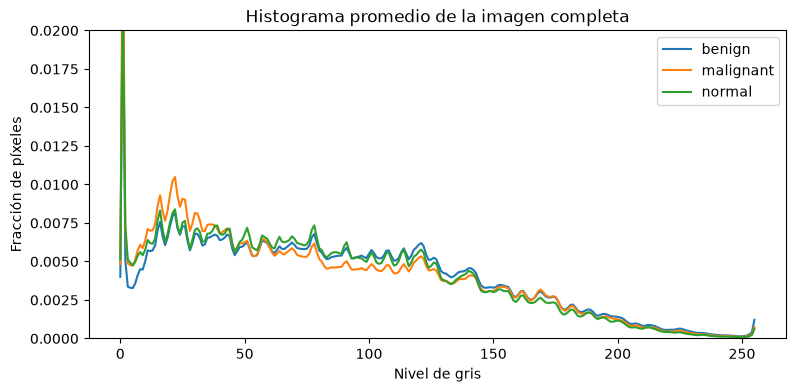

In [12]:
clases = ["benign", "malignant", "normal"]
hist_clase = {c: np.zeros(256) for c in clases}

for _, caso in casos.iterrows():
    img, mascara = cargar_caso(caso)
    h = np.bincount(img.ravel(), minlength=256)   # cuántos píxeles hay de cada nivel 0..255
    hist_clase[caso["clase"]] += h / h.sum()       # normalizado: fracción de píxeles

for c in clases:
    hist_clase[c] /= (casos["clase"] == c).sum()   # promedio de la clase

plt.figure(figsize=(9, 4))
for c in clases:
    plt.plot(hist_clase[c], label=c)
plt.ylim(0, 0.02)          # recortamos el eje para que no lo domine el pico en 0
plt.xlabel("Nivel de gris")
plt.ylabel("Fracción de píxeles")
plt.title("Histograma promedio de la imagen completa")
plt.legend()
plt.show()

**Qué vemos:** las tres curvas son **casi iguales**. La mayoría de los píxeles son oscuros o grises medios (0 a 150) y muy pocos llegan al blanco. El pico en 0 corresponde al fondo negro fuera del sector que barre la sonda.

El **histograma global no distingue las clases**. Tiene sentido: el tumor ocupa una parte chica de la imagen (4 a 12 %) y el resto es tejido parecido en todas. Además, el histograma no tiene información espacial. Esto justifica **analizar la región de la lesión y su textura local** en vez de la imagen entera.

### 5.2 Lesión vs. tejido que la rodea

Ahora comparamos los píxeles **dentro del tumor** (máscara) con los de un **anillo de tejido alrededor** del tumor. El anillo se arma **dilatando** la máscara (operación morfológica de la clase de Segmentación II: agranda la región ~15 px hacia afuera) y quitándole la máscara original: queda solo el borde de tejido que rodea al tumor.

Solo usamos benignas y malignas, porque las normales no tienen lesión.

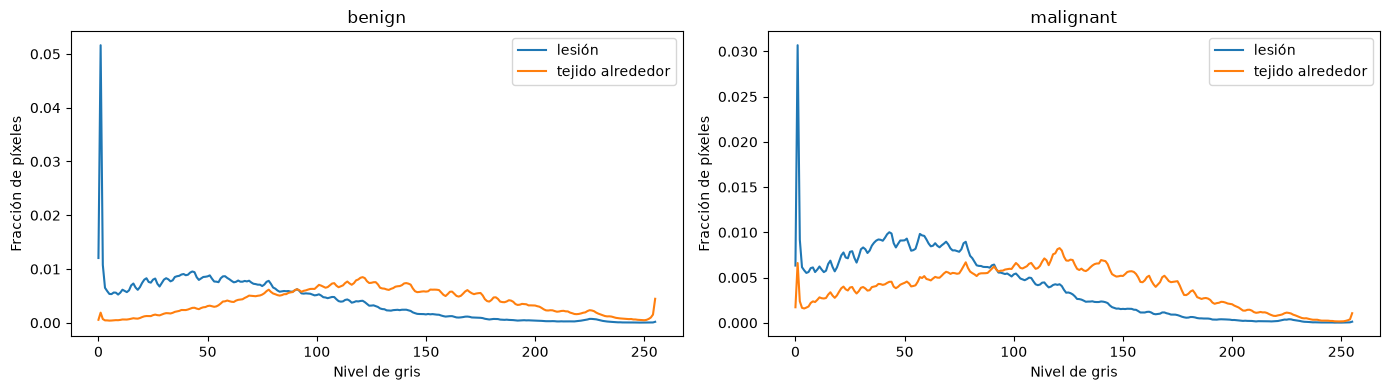

In [13]:
import cv2

disco = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31))   # elemento estructurante: disco de radio 15 px

hist_lesion = {c: np.zeros(256) for c in ["benign", "malignant"]}
hist_anillo = {c: np.zeros(256) for c in ["benign", "malignant"]}
medidas = []

for _, caso in casos[casos["clase"] != "normal"].iterrows():
    img, mascara = cargar_caso(caso)
    dilatada = cv2.dilate(mascara.astype(np.uint8), disco).astype(bool)
    anillo = dilatada & ~mascara                  # tejido alrededor = dilatada menos la lesión

    h_les = np.bincount(img[mascara], minlength=256)
    h_ani = np.bincount(img[anillo], minlength=256)
    hist_lesion[caso["clase"]] += h_les / h_les.sum()
    hist_anillo[caso["clase"]] += h_ani / h_ani.sum()

    medidas.append({
        "clase": caso["clase"],
        "media_lesion": img[mascara].mean(),
        "media_anillo": img[anillo].mean(),
    })

medidas = pd.DataFrame(medidas)
medidas["contraste"] = medidas["media_anillo"] - medidas["media_lesion"]   # cuánto más claro es el tejido que el tumor

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, c in zip(axes, ["benign", "malignant"]):
    n = (casos["clase"] == c).sum()
    ax.plot(hist_lesion[c] / n, label="lesión")
    ax.plot(hist_anillo[c] / n, label="tejido alrededor")
    ax.set_title(c)
    ax.set_xlabel("Nivel de gris")
    ax.set_ylabel("Fracción de píxeles")
    ax.legend()
plt.tight_layout()
plt.show()

**Qué vemos:**
- En las dos clases la **lesión es más oscura** que el tejido que la rodea: su histograma está corrido hacia la izquierda. Es lo que en ecografía se llama lesión **hipoecoica**.
- Hay un **pico en 0 dentro de la lesión**, más marcado en las benignas: zonas totalmente negras (**anecoicas**), típicas de los **quistes**, que son lesiones benignas llenas de líquido.
- Las dos curvas **se superponen bastante**: muchos píxeles del tumor tienen el mismo gris que el tejido.

**Un umbral de intensidad solo no alcanza para segmentar bien**: habría píxeles de tejido clasificados como tumor y al revés. Por eso en la Parte 4 buscamos **mapas de características** (textura local, varianza) que separen mejor la lesión del fondo.

### 5.3 Contraste lesión–tejido por imagen

Resumimos cada imagen con tres números: el gris medio de la lesión, el del tejido alrededor y su diferencia (**contraste**). Un contraste alto significa que el tumor resalta mucho del tejido.

           media_lesion  media_anillo  contraste
clase                                           
benign             66.9         125.5       56.7
malignant          63.6         108.7       43.5


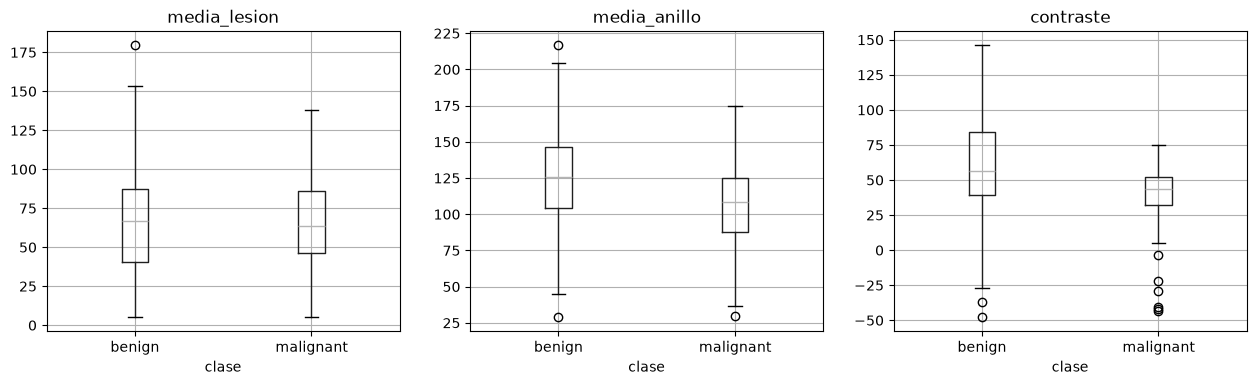

In [14]:
print(medidas.groupby("clase")[["media_lesion", "media_anillo", "contraste"]].median().round(1))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["media_lesion", "media_anillo", "contraste"]):
    medidas.boxplot(column=col, by="clase", ax=ax)
    ax.set_title(col)
plt.suptitle("")
plt.show()

**Qué vemos (medianas):**

| | Lesión | Tejido alrededor | Contraste |
|---|---|---|---|
| Benigna | 67 | 126 | 57 |
| Maligna | 64 | 109 | 44 |

- El interior del tumor tiene un gris parecido en las dos clases.
- En las **malignas el tejido alrededor es más oscuro**, así que el **contraste es menor**: el tumor se distingue menos del tejido. Una posible explicación es que los malignos tienen bordes difusos (halo) y sombra acústica, que oscurecen la zona que los rodea.

Dos consecuencias: (1) los tumores malignos van a ser **más difíciles de segmentar**, y (2) la **ecogenicidad relativa** (contraste lesión–tejido) es un candidato a descriptor para la Parte 6, donde se va a evaluar si la diferencia es estadísticamente significativa.

## 6. Resumen de la exploración

| Aspecto | Resultado | Qué implica para el trabajo |
|---|---|---|
| Clases | 437 benignas, 210 malignas, 133 normales | Desbalance → métricas balanceadas en la Parte 6 |
| Tamaño | Variable: 310–719 px de alto, 190–1048 px de ancho | Ventanas de textura en píxeles, no relativas |
| Formato | PNG, 3 canales, 8 bits (256 niveles) | Se trabaja con un solo canal (gris) |
| Color | 16 imágenes con marcas de color (Doppler, *calipers*, textos) | Pista para detectar marcas en la Parte 1 |
| Rango | Casi todas usan de 0 a 255 | El 255 suele ser marca, no tejido |
| Lesión | Malignas ocupan más (mediana 12 % vs 4 %) | Primera diferencia entre clases |
| Máscaras | 17 imágenes con más de una lesión | Se unen; definir cómo tratarlas en la Parte 6 |
| Histograma global | Casi igual en las tres clases | No sirve para distinguir clases → analizar la lesión y su textura |
| Lesión vs. tejido | Lesión más oscura (hipoecoica) pero con mucha superposición | Un umbral solo no alcanza → mapas de características (Parte 4) |
| Contraste | Menor en malignas (mediana 44 vs 57) | Malignas más difíciles de segmentar; descriptor candidato (Parte 6) |
| Duplicados | Hay imágenes casi idénticas | Revisar antes de entrenar el clasificador |